# ARIMA: Autoregressive Integrated Moving Avarage

We need our data to be stationary for ARIMA/SARIMA.
ARIMA works by learning patterns from past values.
But if the data keeps changing behavior, ARIMA cannot learn stable relationships.

# What is Stationary Data in Time Series?

Stationary data is a time series whose statistical properties do not change over time.

That means:

A stationary time series has:

Constant Mean over time
Constant Variance over time
Constant Autocorrelation structure over time

In simple words:

The data behaves the same way today as it did yesterday and will tomorrow


# **ARIMA Quick Reference **
1. Stationary Data

A time series is stationary if:

• Mean is constant
• Variance is constant
• Pattern does not change over time

Why needed?
ARIMA assumes stable patterns to forecast accurately.

2. Differencing (d)

Used to make data stationary by removing trend.

First Differencing:
[
Y't = Y_t - Y{t-1}
]

Second Differencing:
[
Y''_t = Y't - Y'{t-1}
]

d = number of differencing steps

Example:
ARIMA(1,1,1) → differenced once

3. Autoregressive (AR — p)

Current value depends on past values

AR(1):
[
Y_t = c + \phi_1 Y_{t-1} + \epsilon_t
]

Where:

• ϕ = influence of past value
• ε = random error

p = number of past values used

Example:
AR(2) → uses last 2 values

Stationarity condition:
[
|\phi| < 1
]

4. Moving Average (MA — q)

Uses past forecast errors

MA(1):
[
Y_t = c + \theta_1 \epsilon_{t-1} + \epsilon_t
]

Where:

• θ = influence of past error
• ε = error term

q = number of past errors used

5. ARIMA Model

[
ARIMA(p,d,q)
]

Parameter	Meaning
p	past values (AR)
d	differencing
q	past errors (MA)

Example:

ARIMA(1,1,1)

• Uses previous value
• Differenced once
• Uses previous error

Summary

Stationary → stable data
AR (p) → past values
d → remove trend
MA (q) → past errors

ARIMA = Combine all three

We'll implement ARIMA on aggregate sales first


In [9]:
import pandas as pd
import matplotlib.pyplot as plt

In [10]:
minimal_data = pd.read_csv("../data/minimal_features.csv")
minimal_data['Date'] = pd.to_datetime(minimal_data['Date'])
split_date = '2012-04-10' #for achieving 80/20 split
total_sales = minimal_data.groupby('Date')['Weekly_Sales'].sum().reset_index()

total_sales.head()

,Date,Weekly_Sales
0,2010-02-05,49750740.50
1,2010-02-12,48336677.63
2,2010-02-19,48276993.78
3,2010-02-26,43968571.13
4,2010-03-05,46871470.30


In [11]:
train_agg = total_sales[total_sales["Date"] <= split_date]
test_agg = total_sales[total_sales["Date"] > split_date]

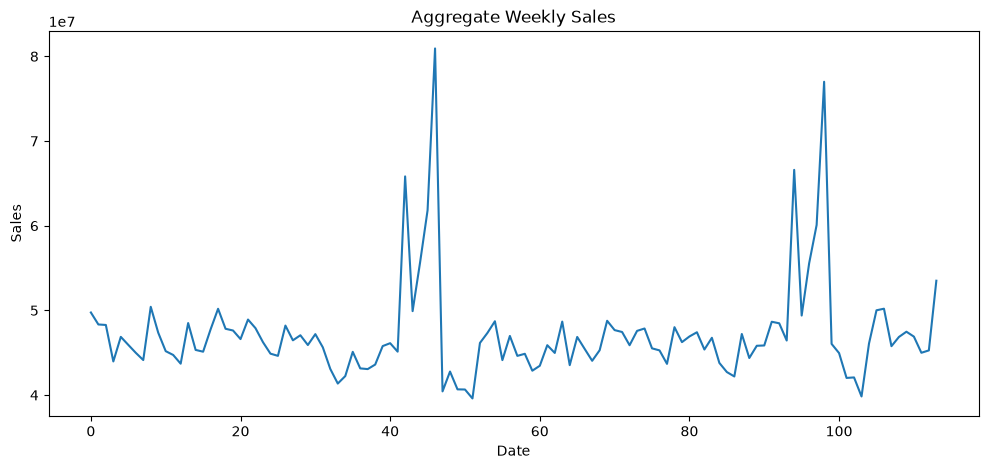

In [12]:
plt.figure(figsize=(12,5))

plt.plot(train_agg.index, train_agg["Weekly_Sales"])
plt.title("Aggregate Weekly Sales")
plt.xlabel("Date")
plt.ylabel("Sales")

plt.show()

From the plot we can obsereve some holiday spikes, which suggests that the data is not stationary, but let's perform more test to know for sure.

**The Augmented Dickey-Fuller (ADF)** test is a statistical method used to determine if a time series is stationary (mean/variance are constant over time). It tests the null hypothesis that a unit root is present (non-stationary). A low p-value (typically
 0.05) indicates stationarity, rejecting the null hypothesis.

In [13]:
#ADF test
from statsmodels.tsa.stattools import adfuller

result = adfuller(train_agg["Weekly_Sales"])

print("ADF Statistic:", result[0])
print("p-value:", result[1])

ADF Statistic: -5.273240474947424
p-value: 6.219568401203441e-06


C:\Users\Admin\AppData\Local\Temp\ipykernel_20248\752716929.py:4: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  result = adfuller(train_agg["Weekly_Sales"])


Huh
p value is vayyy < 0.05 which indicates strong stationarity as well as the ADF statistic < -5 which is also feature of stationarity.

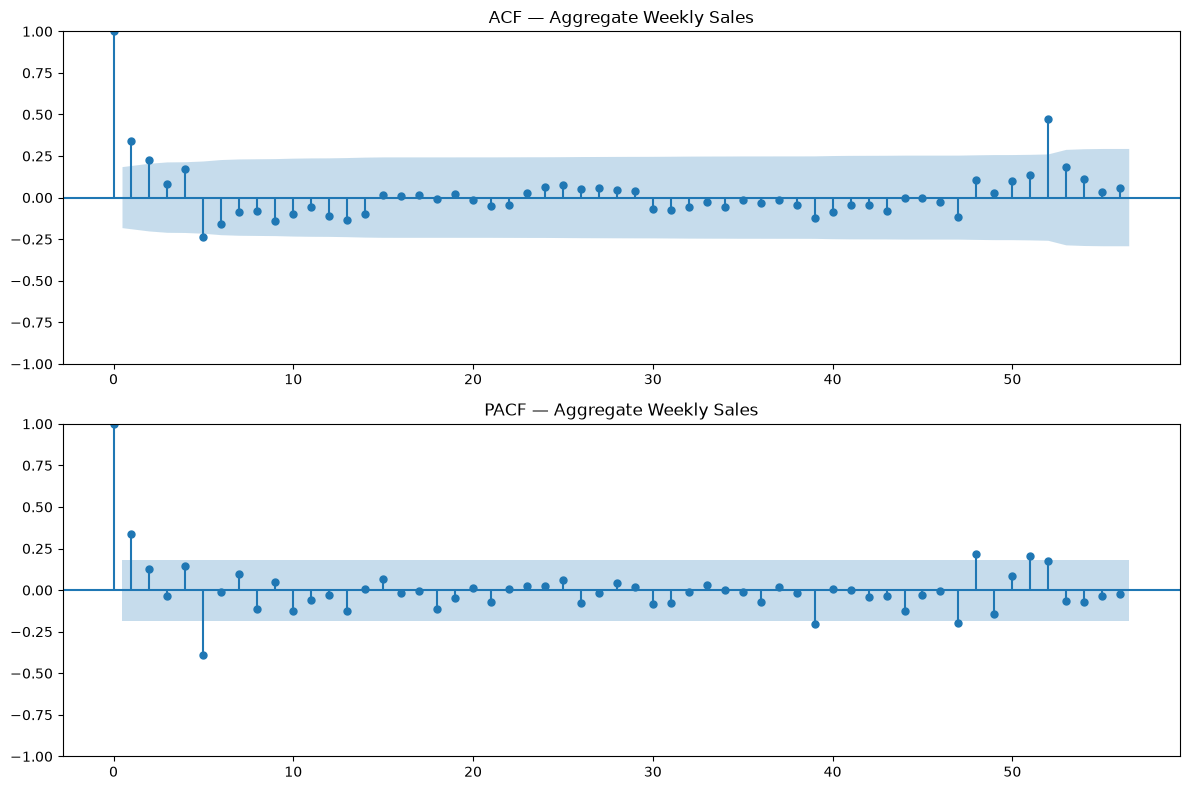

In [14]:
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
#ACF and PACF help choose p and q, they represent the correlation between the series and their own lags
fig, axes = plt.subplots(2, 1, figsize=(12, 8))

plot_acf(train_agg['Weekly_Sales'], lags=56, ax=axes[0])
axes[0].set_title("ACF — Aggregate Weekly Sales")

plot_pacf(train_agg['Weekly_Sales'], lags=56, ax=axes[1])
axes[1].set_title("PACF — Aggregate Weekly Sales")

plt.tight_layout()
plt.show()

In [15]:
pip install pmdarima

Note: you may need to restart the kernel to use updated packages.


before moving on to SARIMA let us use auto_arima that tests the (p, d, q) parameters for us and finds the best one

In [16]:
from pmdarima import auto_arima
# Non-seasonal auto ARIMA (seasonal=False)
auto_model_arima = auto_arima(
    train_agg['Weekly_Sales'],
    seasonal=False,        # plain ARIMA, no seasonality yet
    stepwise=True,
    suppress_warnings=True,
    information_criterion='aic'
)

print(auto_model_arima.summary())
print(f"Best order: {auto_model_arima.order}")

                               SARIMAX Results                                
Dep. Variable:                      y   No. Observations:                  114
Model:               SARIMAX(5, 0, 0)   Log Likelihood               -1922.810
Date:                Sun, 18 Oct 2026   AIC                           3859.621
Time:                        00:14:26   BIC                           3878.774
Sample:                             0   HQIC                          3867.394
                                - 114                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
intercept   3.349e+07   5.29e-10   6.33e+16      0.000    3.35e+07    3.35e+07
ar.L1          0.3637      0.061      5.974      0.000       0.244       0.483
ar.L2          0.0815      0.085      0.957      0.3

In [17]:
#forecasting
forecast_arima = auto_model_arima.predict(n_periods=len(test_agg))

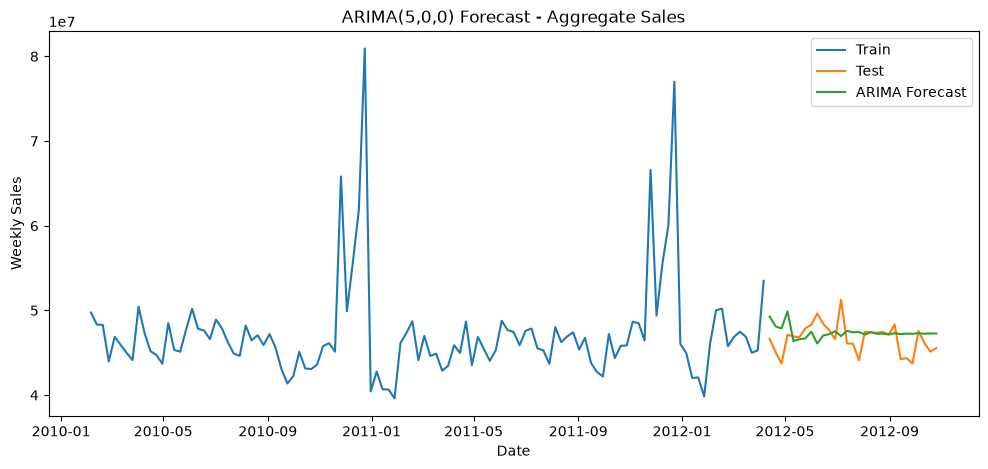

In [18]:
plt.figure(figsize=(12, 5))
plt.plot(train_agg['Date'], train_agg['Weekly_Sales'], label='Train')
plt.plot(test_agg['Date'], test_agg['Weekly_Sales'], label='Test')
plt.plot(test_agg['Date'], forecast_arima, label='ARIMA Forecast')
plt.legend()
plt.title("ARIMA(5,0,0) Forecast - Aggregate Sales")
plt.xlabel("Date")
plt.ylabel("Weekly Sales")
plt.show()

In [19]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np
def evaluate_forecast(y_true, y_pred):
    mae  = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))

    # Exclude zero actuals (MAPE undefined) and NaN predictions
    valid_mask = (y_true != 0) & (~np.isnan(y_pred))
    if valid_mask.sum() == 0:
        mape = np.nan
    else:
        mape = np.mean(np.abs(
            (y_true[valid_mask] - y_pred[valid_mask]) / y_true[valid_mask]
        )) * 100

    return mae, rmse, mape

In [20]:
mae, rmse, mape = evaluate_forecast(
    test_agg['Weekly_Sales'].values,
    forecast_arima
)

print("=== ARIMA(5,0,0) Results ===")
print(f"MAE:  {mae:,.2f}")
print(f"RMSE: {rmse:,.2f}")
print(f"MAPE: {mape:.2f}%")

=== ARIMA(5,0,0) Results ===
MAE:  1,673,010.82
RMSE: 2,136,955.82
MAPE: 3.62%


In [21]:
# Comparison table with Baseline models
data = {
    "Model": ["Naive", "Moving Average (4W)", "Seasonal Naive", "ARIMA (5,0,0)"],
    "MAE": [1648526, 1591869, 1247205, 1673010],
    "RMSE": [2419672, 1901638, 1562916, 2136955],
    "MAPE": ["3.52%", "3.44%", "2.65%", "3.62%"]
}

comparison_df = pd.DataFrame(data)

# Display table
comparison_df

,Model,MAE,RMSE,MAPE
0,Naive,1648526,2419672,3.52%
1,Moving Average (4W),1591869,1901638,3.44%
2,Seasonal Naive,1247205,1562916,2.65%
3,"ARIMA (5,0,0)",1673010,2136955,3.62%


MAE is even higher than naive forecast

MAE = 1,673,010 — on average, the ARIMA forecast is off by about $1.67 million per week across all stores combined. Remember this is aggregate sales, so we're talking tens of millions total weekly — so this is a relative error.

RMSE = 2,136,955 — higher than MAE, which means there are some weeks where the error is much larger than average. Those are likely the holiday spike weeks where ARIMA has no idea a spike is coming.

MAPE = 3.62% — on average the forecast is 3.62% away from the actual value. This is your most interpretable number.


# **The key takeaway**
ARIMA(5,0,0) is worse than all three baselines on MAPE and worse than Seasonal Naive on every metric. It's even slightly worse than the plain Naive forecast.
This is actually the result you want to see at this stage because it tells a clear story:

- ARIMA captures short-term autocorrelation (the last 5 weeks) but has no concept of yearly seasonality
- The holiday spikes it completely misses are large enough to drag all metrics down
- A simple Seasonal Naive that just looks at last year outperforms a sophisticated ARIMA model — because the dominant signal in this data is seasonal, not short-term autocorrelation

ARIMA(5,0,0) selected by auto_arima achieved a MAPE of 3.62%, underperforming all Phase 4 baselines including the simple Seasonal Naive (2.65%). This confirms that short-term autocorrelation alone is insufficient for this dataset — the yearly seasonal pattern is the dominant signal and must be explicitly modelled. This motivates the use of SARIMA in the next step.

In [22]:
#before sarima
train_agg = train_agg.set_index("Date")
test_agg = test_agg.set_index("Date")

# SARIMA

In [23]:
auto_model_sarima = auto_arima(
    train_agg['Weekly_Sales'],
    seasonal=True,
    m=52,                 # weekly seasonality
    stepwise=True,
    suppress_warnings=True,
    information_criterion='aic'
)

print(auto_model_sarima.summary())
print(f"Best SARIMA order: {auto_model_sarima.order}")
print(f"Best Seasonal order: {auto_model_sarima.seasonal_order}")

                                      SARIMAX Results                                      
Dep. Variable:                                   y   No. Observations:                  114
Model:             SARIMAX(2, 0, 2)x(1, 0, [], 52)   Log Likelihood               -1909.227
Date:                             Sun, 18 Oct 2026   AIC                           3832.453
Time:                                     00:15:23   BIC                           3851.606
Sample:                                 02-05-2010   HQIC                          3840.226
                                      - 04-06-2012                                         
Covariance Type:                               opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
intercept   3.061e+07   2.34e-08   1.31e+15      0.000    3.06e+07    3.06e+07
ar.L1         -0.7270      

In [24]:
forecast_sarima = auto_model_sarima.predict(
    n_periods=len(test_agg)
)

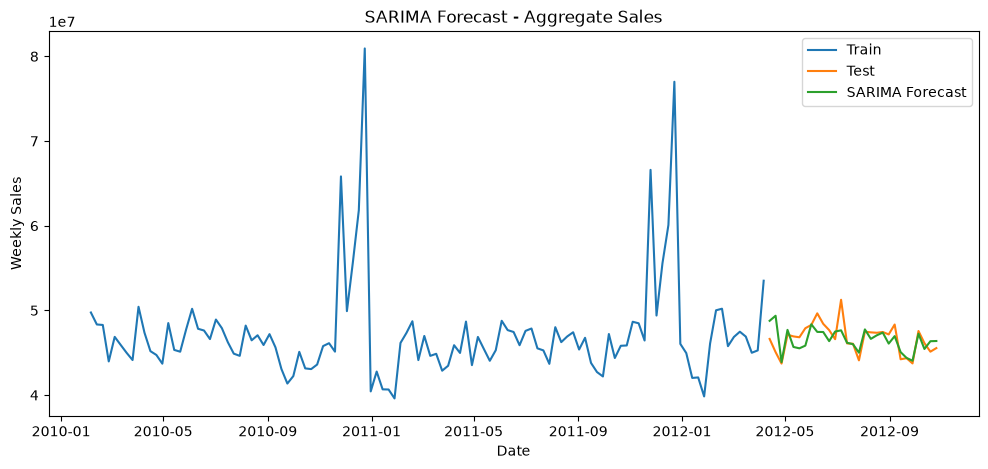

In [25]:
plt.figure(figsize=(12,5))

plt.plot(train_agg.index, train_agg['Weekly_Sales'], label='Train')
plt.plot(test_agg.index, test_agg['Weekly_Sales'], label='Test')
plt.plot(test_agg.index, forecast_sarima, label='SARIMA Forecast')

plt.legend()
plt.title("SARIMA Forecast - Aggregate Sales")
plt.xlabel("Date")
plt.ylabel("Weekly Sales")
plt.show()

# Evaluate SARIMA

In [26]:
mae_sarima, rmse_sarima, mape_sarima = evaluate_forecast(
    test_agg['Weekly_Sales'].values,
    forecast_sarima
)

print("=== SARIMA Results ===")
print(f"MAE: {mae_sarima:,.2f}")
print(f"RMSE: {rmse_sarima:,.2f}")
print(f"MAPE: {mape_sarima:.2f}%")

=== SARIMA Results ===
MAE: 1,034,870.43
RMSE: 1,443,200.21
MAPE: 2.19%


In [27]:
comparison_df = pd.DataFrame({
    "Model": [
        "Naive",
        "Moving Average (4W)",
        "Seasonal Naive",
        "ARIMA (5,0,0)",
        "SARIMA"
    ],
    "MAE": [
        1648526,
        1591869,
        1247205,
        1673010,
        mae_sarima
    ],
    "RMSE": [
        2419672,
        1901638,
        1562916,
        2136955,
        rmse_sarima
    ],
    "MAPE": [
        "3.52%",
        "3.44%",
        "2.65%",
        "3.62%",
        f"{mape_sarima:.2f}%"
    ]
})

comparison_df

,Model,MAE,RMSE,MAPE
0,Naive,1.648526e+06,2.419672e+06,3.52%
1,Moving Average (4W),1.591869e+06,1.901638e+06,3.44%
2,Seasonal Naive,1.247205e+06,1.562916e+06,2.65%
3,"ARIMA (5,0,0)",1.673010e+06,2.136955e+06,3.62%
4,SARIMA,1.034870e+06,1.443200e+06,2.19%


SARIMA achieved the best performance across all evaluation metrics, reducing MAPE from 2.65% (Seasonal Naive) to 2.19%. This confirms that yearly seasonality is the dominant signal in retail sales data, and explicitly modelling seasonal components significantly improves forecast accuracy. The results also highlight that traditional ARIMA models without seasonal components are insufficient for datasets with strong holiday-driven demand patterns.

# Prophet

In [28]:
pip install prophet

Note: you may need to restart the kernel to use updated packages.


In [29]:
from prophet import Prophet

In [30]:
prophet_train = train_agg.reset_index()

prophet_train = prophet_train.rename(
    columns={
        'Date': 'ds',
        'Weekly_Sales': 'y'
    }
)

prophet_train.head()

,ds,y
0,2010-02-05,49750740.50
1,2010-02-12,48336677.63
2,2010-02-19,48276993.78
3,2010-02-26,43968571.13
4,2010-03-05,46871470.30


In [31]:
model_prophet = Prophet(
    yearly_seasonality=True,
    weekly_seasonality=False,
    daily_seasonality=False
)

model_prophet.fit(prophet_train)

c:\Users\Admin\Desktop\retail-demand-forecasting\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
00:15:25 - cmdstanpy - INFO - Chain [1] start processing
00:15:26 - cmdstanpy - INFO - Chain [1] done processing


In [32]:
future = model_prophet.make_future_dataframe(
    periods=len(test_agg),
    freq='W'
)

future.tail()

,ds
138,2012-09-23
139,2012-09-30
140,2012-10-07
141,2012-10-14
142,2012-10-21


In [33]:
forecast_prophet = model_prophet.predict(future)

forecast_prophet.head()

,ds,trend,yhat_lower,yhat_upper,trend_lower,trend_upper,additive_terms,additive_terms_lower,additive_terms_upper,yearly,yearly_lower,yearly_upper,multiplicative_terms,multiplicative_terms_lower,multiplicative_terms_upper,yhat
0,2010-02-05,4.676867e+07,4.228311e+07,5.253287e+07,4.676867e+07,4.676867e+07,7.730014e+05,7.730014e+05,7.730014e+05,7.730014e+05,7.730014e+05,7.730014e+05,0.0,0.0,0.0,4.754167e+07
1,2010-02-12,4.677723e+07,4.347592e+07,5.323868e+07,4.677723e+07,4.677723e+07,1.394310e+06,1.394310e+06,1.394310e+06,1.394310e+06,1.394310e+06,1.394310e+06,0.0,0.0,0.0,4.817154e+07
2,2010-02-19,4.678580e+07,4.221571e+07,5.181071e+07,4.678580e+07,4.678580e+07,1.557730e+04,1.557730e+04,1.557730e+04,1.557730e+04,1.557730e+04,1.557730e+04,0.0,0.0,0.0,4.680138e+07
3,2010-02-26,4.679436e+07,4.074853e+07,5.072264e+07,4.679436e+07,4.679436e+07,-1.079713e+06,-1.079713e+06,-1.079713e+06,-1.079713e+06,-1.079713e+06,-1.079713e+06,0.0,0.0,0.0,4.571465e+07
4,2010-03-05,4.680293e+07,4.047370e+07,5.050297e+07,4.680293e+07,4.680293e+07,-1.273233e+06,-1.273233e+06,-1.273233e+06,-1.273233e+06,-1.273233e+06,-1.273233e+06,0.0,0.0,0.0,4.552970e+07


In [34]:
forecast_values = forecast_prophet['yhat'].iloc[-len(test_agg):].values

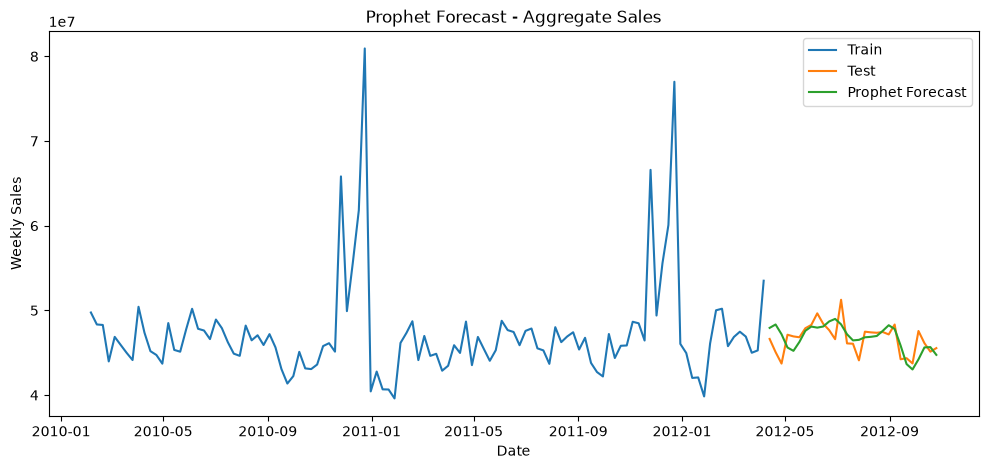

In [35]:
plt.figure(figsize=(12,5))

plt.plot(train_agg.index, train_agg['Weekly_Sales'], label='Train')
plt.plot(test_agg.index, test_agg['Weekly_Sales'], label='Test')
plt.plot(test_agg.index, forecast_values, label='Prophet Forecast')

plt.legend()
plt.title("Prophet Forecast - Aggregate Sales")
plt.xlabel("Date")
plt.ylabel("Weekly Sales")
plt.show()

In [36]:
mae, rmse, mape = evaluate_forecast(
    test_agg['Weekly_Sales'].values,
    forecast_values
)

print("=== Prophet Results ===")
print(f"MAE: {mae:,.2f}")
print(f"RMSE: {rmse:,.2f}")
print(f"MAPE: {mape:.2f}%")

=== Prophet Results ===
MAE: 1,243,596.93
RMSE: 1,594,036.80
MAPE: 2.68%


In [37]:
comparison_data = {
    "Model": [
        "Naive",
        "Moving Average (4W)",
        "Seasonal Naive",
        "ARIMA (5,0,0)",
        "SARIMA",
        "Prophet"
    ],
    "MAE": [
        1648526,
        1591869,
        1247205,
        1673010,
        1034871,
        mae
    ],
    "RMSE": [
        2419672,
        1901638,
        1562916,
        2136955,
        1443201,
        rmse
    ],
    "MAPE": [
        "3.52%",
        "3.44%",
        "2.65%",
        "3.62%",
        "2.19%",
        f"{mape:.2f}%"
    ]
}

comparison_df = pd.DataFrame(comparison_data)

comparison_df

,Model,MAE,RMSE,MAPE
0,Naive,1.648526e+06,2.419672e+06,3.52%
1,Moving Average (4W),1.591869e+06,1.901638e+06,3.44%
2,Seasonal Naive,1.247205e+06,1.562916e+06,2.65%
3,"ARIMA (5,0,0)",1.673010e+06,2.136955e+06,3.62%
4,SARIMA,1.034871e+06,1.443201e+06,2.19%
5,Prophet,1.243597e+06,1.594037e+06,2.68%


SARIMA achieved the best performance with a MAPE of 2.19%, outperforming all baseline models and Prophet. Although Prophet is designed for business forecasting and holiday-driven demand, SARIMA performed better due to the relatively stable yearly seasonal structure of the dataset. This suggests that classical statistical models remain highly competitive for retail demand forecasting when seasonality is consistent and the dataset is moderately sized.